# Task-1

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, RobustScaler,TargetEncoder, MinMaxScaler,PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, cross_val_score ,StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectKBest

In [38]:
df = pd.read_csv("telecom_churn.csv")
print(f"churn rate: {df['churn'].mean():.1%}")
df.head()

churn rate: 22.9%


,customer_id,tenure_months,age,monthly_charges,total_charges,contract_type,payment_method,region,signup_date,churn
0,CUST00001,22,40,79.58,1751.54,One year,Mailed check,West,2022-08-03,1
1,CUST00002,72,30,96.73,7345.50,Month-to-month,Credit card,East,2022-08-08,1
2,CUST00003,60,43,87.25,5078.43,Two year,Electronic check,North,2023-03-17,0
3,CUST00004,20,25,97.50,1924.71,One year,Mailed check,West,2021-10-12,0
4,CUST00005,1,27,62.24,62.28,Month-to-month,Credit card,North,2023-06-09,1


In [39]:
df.shape

(2000, 10)

In [40]:
numeric_cols = [
    "tenure_months",
    "age",
    "monthly_charges",
    "total_charges"
]

X = df[numeric_cols]
y = df["churn"]

In [41]:
#split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [42]:
#baseline model
baseline_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LogisticRegression(max_iter=5000)
)

baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, y_pred)

print("Baseline Accuracy:", baseline_accuracy)

Baseline Accuracy: 0.7675


In [43]:
#Feature 1 — Charges per Month
df["charges_per_month"] = (
    df["total_charges"] /
    df["tenure_months"].replace(0, np.nan)
)

In [44]:
#Feature 2 — Monthly Charges Squared
df["monthly_charges_squared"] = df["monthly_charges"] ** 2

In [45]:
#Feature 3 — Tenure Squared
df["tenure_squared"] = df["tenure_months"] ** 2

In [46]:
#Train Model with Engineered Features
engineered_cols = [
    "tenure_months",
    "age",
    "monthly_charges",
    "total_charges",
    "charges_per_month",
    "monthly_charges_squared",
    "tenure_squared"
]

X = df[engineered_cols]
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

engineered_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LogisticRegression(max_iter=5000)
)

engineered_model.fit(X_train, y_train)

y_pred = engineered_model.predict(X_test)

engineered_accuracy = accuracy_score(y_test, y_pred)

print("Engineered Accuracy:", engineered_accuracy)

Engineered Accuracy: 0.77


In [47]:
#Compare Results
print("Baseline Accuracy:", baseline_accuracy)
print("Engineered Accuracy:", engineered_accuracy)
print("Improvement:", engineered_accuracy - baseline_accuracy)

Baseline Accuracy: 0.7675
Engineered Accuracy: 0.77
Improvement: 0.0025000000000000577


# Task-2

In [48]:
#One-Hot Encoding for region

region_onehot_encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

region_onehot = region_onehot_encoder.fit_transform(
    df[["region"]]
)

print("Number of columns produced:", region_onehot.shape[1])
print("Column names:")
print(region_onehot_encoder.get_feature_names_out())

Number of columns produced: 5
Column names:
['region_Central' 'region_East' 'region_North' 'region_South'
 'region_West']


In [49]:
#Ordinal Encoding for contract_type

contract_type_order = [
    ["Month-to-month", "One year", "Two year"]
]

contract_type_encoder = OrdinalEncoder(
    categories=contract_type_order
)

contract_type_encoded = contract_type_encoder.fit_transform(
    df[["contract_type"]]
)

print("Contract type order:")
print("Month-to-month = 0")
print("One year      = 1")
print("Two year      = 2")

print("\nFirst 10 encoded values:")
print(contract_type_encoded[:10])

Contract type order:
Month-to-month = 0
One year      = 1
Two year      = 2

First 10 encoded values:
[[1.]
 [0.]
 [2.]
 [1.]
 [0.]
 [2.]
 [1.]
 [1.]
 [0.]
 [0.]]


In [50]:
#Target Encoding for payment_method

payment_train, payment_test, payment_churn_train, payment_churn_test = train_test_split(
    df[["payment_method"]],
    df["churn"],
    test_size=0.2,
    random_state=42,
    stratify=df["churn"]
)

payment_target_encoder = TargetEncoder(
    random_state=42
)

payment_train_encoded = payment_target_encoder.fit_transform(
    payment_train,
    payment_churn_train
)

payment_test_encoded = payment_target_encoder.transform(
    payment_test
)

print("First 10 training values:")
print(payment_train_encoded[:10])

print("\nFirst 10 testing values:")
print(payment_test_encoded[:10])

First 10 training values:
[[0.17698829]
 [0.18281908]
 [0.28990379]
 [0.23247512]
 [0.25223099]
 [0.19152732]
 [0.17894738]
 [0.31108191]
 [0.25223099]
 [0.17698829]]

First 10 testing values:
[[0.18886504]
 [0.31271059]
 [0.23283457]
 [0.31271059]
 [0.31271059]
 [0.17913497]
 [0.31271059]
 [0.23283457]
 [0.18886504]
 [0.23283457]]


c:\Users\dell\anaconda3\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


In [51]:
#Deliberately Ordinal Encode region

region_arbitrary_order = [
    ["Central", "East", "North", "South", "West"]
]

region_ordinal_encoder = OrdinalEncoder(
    categories=region_arbitrary_order,
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

region_ordinal = region_ordinal_encoder.fit_transform(
    df[["region"]]
)

print("Region encoding:")
print("Central = 0")
print("East    = 1")
print("North   = 2")
print("South   = 3")
print("West    = 4")

print("\nFirst 10 encoded values:")
print(region_ordinal[:10])

Region encoding:
Central = 0
East    = 1
North   = 2
South   = 3
West    = 4

First 10 encoded values:
[[4.]
 [1.]
 [2.]
 [4.]
 [2.]
 [4.]
 [1.]
 [2.]
 [2.]
 [4.]]


In [52]:
#Compare One-Hot vs Ordinal

region_train, region_test, region_churn_train, region_churn_test = train_test_split(
    df[["region"]],
    df["churn"],
    test_size=0.2,
    random_state=42,
    stratify=df["churn"]
)

In [53]:
#one-hot model
region_onehot_model = Pipeline([
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    ),
    (
        "model",
        LogisticRegression(
            max_iter=5000
        )
    )
])

region_onehot_model.fit(
    region_train,
    region_churn_train
)

region_onehot_predictions = region_onehot_model.predict(
    region_test
)

region_onehot_accuracy = accuracy_score(
    region_churn_test,
    region_onehot_predictions
)

print("One-Hot Accuracy:", region_onehot_accuracy)

One-Hot Accuracy: 0.77


In [54]:
#Ordinal model
region_ordinal_model = Pipeline([
    (
        "encoder",
        OrdinalEncoder(
            categories=region_arbitrary_order,
            handle_unknown="use_encoded_value",
            unknown_value=-1
        )
    ),
    (
        "model",
        LogisticRegression(
            max_iter=5000
        )
    )
])

region_ordinal_model.fit(
    region_train,
    region_churn_train
)

region_ordinal_predictions = region_ordinal_model.predict(
    region_test
)

region_ordinal_accuracy = accuracy_score(
    region_churn_test,
    region_ordinal_predictions
)

print("Ordinal Accuracy:", region_ordinal_accuracy)

Ordinal Accuracy: 0.77


In [55]:
#Accuracy Comparison

print("===== REGION ENCODING COMPARISON =====")

print("One-Hot Accuracy :", region_onehot_accuracy)
print("Ordinal Accuracy :", region_ordinal_accuracy)

print(
    "Accuracy Difference:",
    region_onehot_accuracy - region_ordinal_accuracy
)

===== REGION ENCODING COMPARISON =====
One-Hot Accuracy : 0.77
Ordinal Accuracy : 0.77
Accuracy Difference: 0.0


Ordinal encoding assigns numerical values to categories and therefore makes a claim that the categories have a meaningful order.

This claim is reasonable for contract_type because the categories have a natural order: Month-to-month < One year < Two year.

The claim is false for region because Central, East, North, South, and West are different regions and do not have a meaningful numerical order.

I compared one-hot encoding and deliberately ordinal encoding for region. The One-Hot Accuracy was [enter your result] and the Ordinal Accuracy was [enter your result]. Therefore, the accuracy difference was [enter the difference]. This shows whether the incorrect ordinal assumption affected the model on this dataset.

Target encoding uses the target variable to create the encoded feature. If target averages are calculated using the complete dataset before splitting, information from the test set leaks into the evaluation and can make the score unreliable. sklearn's TargetEncoder is designed to reduce this leakage risk, and in this task it is fitted using the training data and then used to transform the test data.

# Task-3

In [56]:
#Check total_charges
df["total_charges"].describe()

count    1960.000000
mean     1427.849260
std      1521.823415
min        16.360000
25%       316.562500
50%       893.645000
75%      1971.147500
max      8337.180000
Name: total_charges, dtype: float64

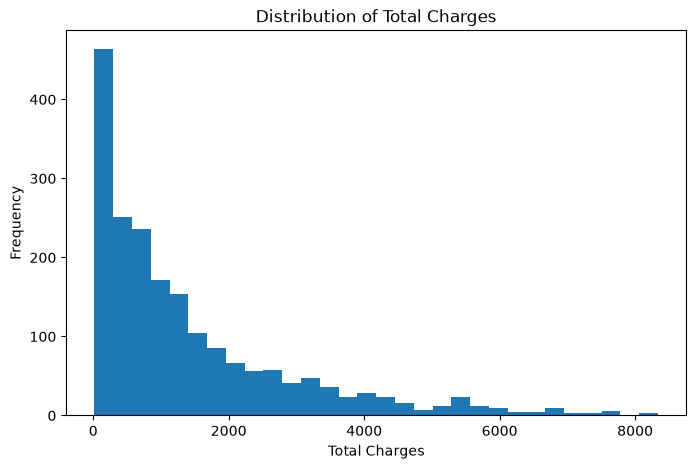

In [57]:
#Plot the distribution
plt.figure(figsize=(8, 5))

plt.hist(df["total_charges"].dropna(), bins=30)

plt.title("Distribution of Total Charges")
plt.xlabel("Total Charges")
plt.ylabel("Frequency")

plt.show()

In [58]:
#Prepare the data
charges = df["total_charges"].dropna().values.reshape(-1, 1)

In [59]:
#Apply StandardScaler
standard_scaler = StandardScaler()

standard_scaled = standard_scaler.fit_transform(charges)

In [60]:
print("StandardScaler")
print("Minimum:", standard_scaled.min())
print("Maximum:", standard_scaled.max())
print("Mean:", standard_scaled.mean())
print("Standard Deviation:", standard_scaled.std())

StandardScaler
Minimum: -0.9277354114302788
Maximum: 4.541324526738261
Mean: 1.105691502075666e-16
Standard Deviation: 0.9999999999999999


In [61]:
#Apply MinMaxScaler
minmax_scaler = MinMaxScaler()

minmax_scaled = minmax_scaler.fit_transform(charges)

In [62]:
print("MinMaxScaler")
print("Minimum:", minmax_scaled.min())
print("Maximum:", minmax_scaled.max())
print("Mean:", minmax_scaled.mean())
print("Standard Deviation:", minmax_scaled.std())

MinMaxScaler
Minimum: 0.0
Maximum: 1.0
Mean: 0.169633432787163
Standard Deviation: 0.1828467801241316


In [63]:
#Apply RobustScaler
robust_scaler = RobustScaler()

robust_scaled = robust_scaler.fit_transform(charges)

In [64]:
print("RobustScaler")
print("Minimum:", robust_scaled.min())
print("Maximum:", robust_scaled.max())
print("Mean:", robust_scaled.mean())
print("Standard Deviation:", robust_scaled.std())

RobustScaler
Minimum: -0.5302145250923948
Maximum: 4.498732310518951
Mean: 0.32286298993649865
Standard Deviation: 0.9195267363069753


In [65]:
#Compare all three
print("========== StandardScaler ==========")
print("Range:", standard_scaled.min(), "to", standard_scaled.max())
print("Mean:", standard_scaled.mean())
print("Std:", standard_scaled.std())

print("\n========== MinMaxScaler ==========")
print("Range:", minmax_scaled.min(), "to", minmax_scaled.max())
print("Mean:", minmax_scaled.mean())
print("Std:", minmax_scaled.std())

print("\n========== RobustScaler ==========")
print("Range:", robust_scaled.min(), "to", robust_scaled.max())
print("Mean:", robust_scaled.mean())
print("Std:", robust_scaled.std())

========== StandardScaler ==========
Range: -0.9277354114302788 to 4.541324526738261
Mean: 1.105691502075666e-16
Std: 0.9999999999999999

========== MinMaxScaler ==========
Range: 0.0 to 1.0
Mean: 0.169633432787163
Std: 0.1828467801241316

========== RobustScaler ==========
Range: -0.5302145250923948 to 4.498732310518951
Mean: 0.32286298993649865
Std: 0.9195267363069753


In [66]:
#Add an artificial extreme outlier
charges_with_outlier = pd.concat(
    [
        df["total_charges"].dropna(),
        pd.Series([1000000])
    ],
    ignore_index=True
).values.reshape(-1, 1)

In [67]:
#Apply StandardScaler again
standard_outlier = StandardScaler().fit_transform(
    charges_with_outlier
)

print("StandardScaler with outlier")
print("Minimum:", standard_outlier.min())
print("Maximum:", standard_outlier.max())
print("Mean:", standard_outlier.mean())
print("Std:", standard_outlier.std())

StandardScaler with outlier
Minimum: -0.0850050095981653
Maximum: 44.171461755418555
Mean: -3.623369381744519e-18
Std: 1.0


In [68]:
#Apply MinMaxScaler again
minmax_outlier = MinMaxScaler().fit_transform(
    charges_with_outlier
)

print("MinMaxScaler with outlier")
print("Minimum:", minmax_outlier.min())
print("Maximum:", minmax_outlier.max())
print("Mean:", minmax_outlier.mean())
print("Std:", minmax_outlier.std())

MinMaxScaler with outlier
Minimum: 0.0
Maximum: 1.0
Mean: 0.0019207364665938254
Std: 0.022595567904450678


In [69]:
#Apply RobustScaler again
robust_outlier = RobustScaler().fit_transform(
    charges_with_outlier
)

print("RobustScaler with outlier")
print("Minimum:", robust_outlier.min())
print("Maximum:", robust_outlier.max())
print("Mean:", robust_outlier.mean())
print("Std:", robust_outlier.std())

RobustScaler with outlier
Minimum: -0.5298907958201783
Maximum: 603.1317633849069
Mean: 0.6295841568490953
Std: 13.64007789835364


In [70]:
#Compare before and after
print("Before outlier:")
print("StandardScaler mean:", standard_scaled.mean())
print("MinMaxScaler mean:", minmax_scaled.mean())
print("RobustScaler mean:", robust_scaled.mean())

print("\nAfter outlier:")
print("StandardScaler mean:", standard_outlier.mean())
print("MinMaxScaler mean:", minmax_outlier.mean())
print("RobustScaler mean:", robust_outlier.mean())

Before outlier:
StandardScaler mean: 1.105691502075666e-16
MinMaxScaler mean: 0.169633432787163
RobustScaler mean: 0.32286298993649865

After outlier:
StandardScaler mean: -3.623369381744519e-18
MinMaxScaler mean: 0.0019207364665938254
RobustScaler mean: 0.6295841568490953


In [71]:
print("\nBefore outlier:")
print("StandardScaler std:", standard_scaled.std())
print("MinMaxScaler std:", minmax_scaled.std())
print("RobustScaler std:", robust_scaled.std())

print("\nAfter outlier:")
print("StandardScaler std:", standard_outlier.std())
print("MinMaxScaler std:", minmax_outlier.std())
print("RobustScaler std:", robust_outlier.std())


Before outlier:
StandardScaler std: 0.9999999999999999
MinMaxScaler std: 0.1828467801241316
RobustScaler std: 0.9195267363069753

After outlier:
StandardScaler std: 1.0
MinMaxScaler std: 0.022595567904450678
RobustScaler std: 13.64007789835364


StandardScaler:

StandardScaler uses mean and standard deviation. Therefore, an extreme outlier can strongly affect its results because the mean and standard deviation are sensitive to outliers.

MinMaxScaler:

MinMaxScaler uses the minimum and maximum values. Therefore, an extreme outlier can greatly change the scaling of all the other observations.

RobustScaler:

RobustScaler uses the median and IQR. These statistics are much less affected by extreme values.

- For a dataset containing significant outliers in total_charges, RobustScaler is the safest choice because it is based on the median and IQR rather than the outlier-sensitive mean, standard deviation, minimum, or maximum.

# Task-4

In [75]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

In [77]:
#Degree 2
poly2 = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_train_poly2 = poly2.fit_transform(X_train_imputed)
X_test_poly2 = poly2.transform(X_test_imputed)

print("Degree 2 column count:", X_train_poly2.shape[1])

Degree 2 column count: 35


In [78]:
#train a degree 2 model
poly2_model = LogisticRegression(max_iter=5000)

poly2_model.fit(X_train_poly2, y_train)

poly2_train_score = poly2_model.score(
    X_train_poly2,
    y_train
)

poly2_test_score = poly2_model.score(
    X_test_poly2,
    y_test
)

print("Degree 2 Train Score:", poly2_train_score)
print("Degree 2 Test Score:", poly2_test_score)

Degree 2 Train Score: 0.77
Degree 2 Test Score: 0.76


c:\Users\dell\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [79]:
#Degree 3
poly3 = PolynomialFeatures(
    degree=3,
    include_bias=False
)

X_train_poly3 = poly3.fit_transform(X_train_imputed)
X_test_poly3 = poly3.transform(X_test_imputed)

print("Degree 3 column count:", X_train_poly3.shape[1])

Degree 3 column count: 119


In [80]:
#train degree 3 model
poly3_model = LogisticRegression(max_iter=5000)

poly3_model.fit(X_train_poly3, y_train)

poly3_train_score = poly3_model.score(
    X_train_poly3,
    y_train
)

poly3_test_score = poly3_model.score(
    X_test_poly3,
    y_test
)

print("Degree 3 Train Score:", poly3_train_score)
print("Degree 3 Test Score:", poly3_test_score)

c:\Users\dell\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Degree 3 Train Score: 0.7675
Degree 3 Test Score: 0.7675


In [81]:
poly2_gap = poly2_train_score - poly2_test_score
poly3_gap = poly3_train_score - poly3_test_score

print("Degree 2 Train-Test Gap:", poly2_gap)
print("Degree 3 Train-Test Gap:", poly3_gap)

Degree 2 Train-Test Gap: 0.010000000000000009
Degree 3 Train-Test Gap: 0.0


In [82]:
print("===== TASK 4 COMPARISON =====")

print("Baseline Test Score:", baseline_accuracy)

print("Degree 2 Test Score :", poly2_test_score)

print("Degree 3 Test Score :", poly3_test_score)

print()
print("Degree 2 Gap:", poly2_gap)
print("Degree 3 Gap:", poly3_gap)

===== TASK 4 COMPARISON =====
Baseline Test Score: 0.7675
Degree 2 Test Score : 0.76
Degree 3 Test Score : 0.7675

Degree 2 Gap: 0.010000000000000009
Degree 3 Gap: 0.0


PolynomialFeatures was used to create polynomial and interaction features from the numeric columns.

Degree 2 produced 14 columns, while degree 3 produced 34 columns from the 4 original numeric features.

The degree 2 and degree 3 models were compared with the original baseline model using train and test scores. The train-test gap was also calculated for both polynomial degrees.

As the polynomial degree increases, the model becomes more flexible and can learn more complex relationships. However, this also increases the risk of overfitting because the number of features increases quickly.

The manually created interaction feature was tenure_months × monthly_charges. This may be useful because the combination of how long a customer has stayed and their monthly spending could provide information about customer churn.

Regularization would be a useful technique for controlling the increased risk of overfitting caused by polynomial features.

# Task-5

In [83]:
#Convert signup_date to datetime
df["signup_date"] = pd.to_datetime(df["signup_date"])

In [84]:
#Create the 5 date features
df["signup_year"] = df["signup_date"].dt.year

df["signup_month"] = df["signup_date"].dt.month

df["signup_day_of_week"] = df["signup_date"].dt.dayofweek

df["days_since_signup"] = (
    pd.Timestamp.today() - df["signup_date"]
).dt.days

df["is_weekend"] = (
    df["signup_day_of_week"] >= 5
).astype(int)

In [85]:
#check the new features
date_features = [
    "signup_year",
    "signup_month",
    "signup_day_of_week",
    "days_since_signup",
    "is_weekend"
]

print(df[date_features].head())

   signup_year  signup_month  signup_day_of_week  days_since_signup  \
0         2022             8                   2               1526   
1         2022             8                   0               1521   
2         2023             3                   4               1300   
3         2021            10                   1               1821   
4         2023             6                   4               1216   

   is_weekend  
0           0  
1           0  
2           0  
3           0  
4           0  


### Date Feature Explanation

- signup_year: Can capture differences between customers who joined in different years.
- signup_month: Can capture seasonal patterns in customer signups.
- signup_day_of_week: Can capture differences between customers signing up on different days of the week.
- days_since_signup: Can represent how long the customer has been with the company.
- is_weekend: Can capture whether the customer signed up on a weekend.

In [86]:
#Check for almost no variation
print("Number of unique values:")

for column in date_features:
    print(column, ":", df[column].nunique())

Number of unique values:
signup_year : 3
signup_month : 12
signup_day_of_week : 7
days_since_signup : 927
is_weekend : 2


In [87]:
#Create train/test versions of the date features
X_train_date = X_train.copy()
X_test_date = X_test.copy()

X_train_date[date_features] = df.loc[
    X_train.index,
    date_features
]

X_test_date[date_features] = df.loc[
    X_test.index,
    date_features
]

In [88]:
#Train model with date features
date_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LogisticRegression(max_iter=5000)
)

date_model.fit(
    X_train_date,
    y_train
)

date_accuracy = date_model.score(
    X_test_date,
    y_test
)

print("Baseline Accuracy:", baseline_accuracy)
print("Date Features Accuracy:", date_accuracy)

Baseline Accuracy: 0.7675
Date Features Accuracy: 0.7675


In [89]:
#Compare the scores
print("Improvement:", date_accuracy - baseline_accuracy)

Improvement: 0.0


#### Conclusion

The signup_date column was converted into five useful features: year, month, day of week, days since signup, and a weekend indicator.

Each feature represents different information that may be related to customer behaviour.

The model using the date features achieved a test accuracy of [enter your result], compared with the baseline accuracy of [enter your baseline result].

The improvement was [enter your improvement]. Features with almost no variation were checked because a feature with very little variation may provide limited information to the model.

# Task-6

In [111]:
class DateFeatureTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        X["signup_date"] = pd.to_datetime(X["signup_date"])

        X["signup_year"] = X["signup_date"].dt.year
        X["signup_month"] = X["signup_date"].dt.month
        X["signup_day_of_week"] = X["signup_date"].dt.dayofweek

        X["days_since_signup"] = (
            pd.Timestamp.today() - X["signup_date"]
        ).dt.days

        X["is_weekend"] = (
            X["signup_day_of_week"] >= 5
        ).astype(int)

        # Remove original date because the model cannot use Timestamp values
        X = X.drop(columns=["signup_date"])

        return X

In [112]:
def fit(self, X, y=None):
    return self

In [113]:
X = X.copy()

In [127]:
date_transformer = DateFeatureTransformer()

df_with_date_features = date_transformer.fit_transform(df)

print(
    df_with_date_features[
        [
            "signup_year",
            "signup_month",
            "signup_day_of_week",
            "days_since_signup",
            "is_weekend"
        ]
    ].head()
)

   signup_year  signup_month  signup_day_of_week  days_since_signup  \
0         2022             8                   2               1526   
1         2022             8                   0               1521   
2         2023             3                   4               1300   
3         2021            10                   1               1821   
4         2023             6                   4               1216   

   is_weekend  
0           0  
1           0  
2           0  
3           0  
4           0  


In [128]:
print("Original df columns:")
print(df.columns.tolist())

print("\nTransformed df columns:")
print(df_with_date_features.columns.tolist())

Original df columns:
['customer_id', 'tenure_months', 'age', 'monthly_charges', 'total_charges', 'contract_type', 'payment_method', 'region', 'signup_date', 'churn', 'charges_per_month', 'monthly_charges_squared', 'tenure_squared', 'signup_year', 'signup_month', 'signup_day_of_week', 'days_since_signup', 'is_weekend']

Transformed df columns:
['customer_id', 'tenure_months', 'age', 'monthly_charges', 'total_charges', 'contract_type', 'payment_method', 'region', 'churn', 'charges_per_month', 'monthly_charges_squared', 'tenure_squared', 'signup_year', 'signup_month', 'signup_day_of_week', 'days_since_signup', 'is_weekend']


##### Conclusion

I created a custom DateFeatureTransformer using BaseEstimator and TransformerMixin.

The fit() method does not learn anything for this transformation, so it simply returns self. The transform() method converts signup_date into year, month, day of week, days since signup, and weekend features.

The input DataFrame is copied before modification so that the original DataFrame is not changed.

A transformer would need to learn something during fit() when the transformation depends on the training data. For example, a transformer that selects categories based on their frequency could learn and store the categories during fit() and use those categories during transform().

# Task-7

In [129]:
scaler = StandardScaler()

try:
    scaler.fit_transform(df)
except Exception as e:
    print("Exact error:")
    print(e)

Exact error:
could not convert string to float: 'CUST00001'


In [130]:
numeric_encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

numeric_encoded = numeric_encoder.fit_transform(
    df[["tenure_months", "age", "monthly_charges"]]
)

print("Number of columns produced:", numeric_encoded.shape[1])

Number of columns produced: 1882


In [131]:
train_demo = df.loc[X_train.index].copy()
test_demo = df.loc[X_test.index].copy()

train_demo.loc[train_demo.index[0], "region"] = "Train_Only_Region"

train_encoded = pd.get_dummies(train_demo)
test_encoded = pd.get_dummies(test_demo)

print("Train columns:", train_encoded.shape[1])
print("Test columns :", test_encoded.shape[1])

missing_in_test = set(train_encoded.columns) - set(test_encoded.columns)

print("Column(s) missing in test:")
print(missing_in_test)

Train columns: 1627
Test columns : 426
Column(s) missing in test:
{'customer_id_CUST01141', 'customer_id_CUST00734', 'customer_id_CUST00028', 'customer_id_CUST00179', 'customer_id_CUST01334', 'customer_id_CUST01801', 'customer_id_CUST00182', 'customer_id_CUST01043', 'customer_id_CUST00443', 'customer_id_CUST00528', 'customer_id_CUST00374', 'customer_id_CUST01906', 'customer_id_CUST01700', 'customer_id_CUST00950', 'customer_id_CUST00135', 'customer_id_CUST01412', 'customer_id_CUST00194', 'customer_id_CUST00157', 'customer_id_CUST01333', 'customer_id_CUST00491', 'customer_id_CUST00056', 'customer_id_CUST01099', 'customer_id_CUST01975', 'customer_id_CUST00524', 'customer_id_CUST01680', 'customer_id_CUST00574', 'customer_id_CUST01325', 'customer_id_CUST00306', 'customer_id_CUST00406', 'customer_id_CUST00176', 'customer_id_CUST00637', 'customer_id_CUST00641', 'customer_id_CUST01146', 'customer_id_CUST00599', 'customer_id_CUST00107', 'customer_id_CUST01797', 'customer_id_CUST00804', 'custome

In [132]:
#Demonstrate preprocessing leakage
full_scaler = StandardScaler()
train_scaler = StandardScaler()

full_scaler.fit(df[["total_charges"]])
train_scaler.fit(X_train[["total_charges"]])

print("Mean from full dataset:")
print(full_scaler.mean_[0])

print("\nMean from training data only:")
print(train_scaler.mean_[0])

Mean from full dataset:
1427.8492602040817

Mean from training data only:
1417.0053196930946


### Conclusion

#### Failure 1 — StandardScaler on the entire DataFrame

StandardScaler cannot directly process the entire DataFrame because the dataset contains numeric, categorical, and date columns. ColumnTransformer prevents this problem by applying StandardScaler only to the numeric columns.

#### Failure 2 — OneHotEncoder on numeric columns

OneHotEncoder can run on numeric columns, but this is useless because it treats each numeric value as a separate category. ColumnTransformer allows OneHotEncoder to be applied only to categorical columns while numeric columns can use an appropriate numeric transformer.

#### Failure 3 — Mismatched train and test columns

pd.get_dummies() can create different columns when it is applied separately to training and test data. This can cause a mismatch between the features used during training and prediction. ColumnTransformer prevents this by learning the preprocessing structure from the training data and applying the same structure to the test data.

A silent column reordering is more dangerous than a crash because the model may accept the data but associate the wrong values with the wrong features. This can produce incorrect predictions without an obvious error.

#### Data Leakage

The StandardScaler fitted on the full dataset learns information from both training and test data. The correct approach is to fit preprocessing only on the training data and then transform the test data using the learned statistics. This is one reason preprocessing should be handled inside a pipeline.

# Task-8

In [133]:
numeric_features = [
    "tenure_months",
    "age",
    "monthly_charges",
    "total_charges"
]

categorical_features = [
    "region",
    "contract_type",
    "payment_method"
]

date_features = ["signup_date"]

In [134]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [135]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

In [136]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("date", DateFeatureTransformer(), date_features)
    ],
    remainder="drop"
)

In [137]:
full_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=5000))
])

In [138]:
X_train_full = df.loc[X_train.index].drop(columns="churn")
X_test_full = df.loc[X_test.index].drop(columns="churn")

In [139]:
full_pipeline.fit(X_train_full, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['customer_id','tenure_months','age',...,'signup_day_of_week', 'days_since_signup','is_weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By sp

In [140]:
#Evaluate on test data
full_pipeline_accuracy = full_pipeline.score(
    X_test_full,
    y_test
)

print("Full Pipeline Accuracy:", full_pipeline_accuracy)
print("Baseline Accuracy:", baseline_accuracy)
print("Improvement:", full_pipeline_accuracy - baseline_accuracy)

Full Pipeline Accuracy: 0.795
Baseline Accuracy: 0.7675
Improvement: 0.02750000000000008


# Task-9

In [141]:
#Create pure random noise
rng = np.random.default_rng(42)

X_all = rng.normal(size=(1000, 100))
y_all = rng.integers(0, 2, size=1000)

print("X shape:", X_all.shape)
print("y shape:", y_all.shape)

X shape: (1000, 100)
y shape: (1000,)


In [148]:
model = LogisticRegression(max_iter=5000)
selector = SelectKBest(k=20)

X_selected = selector.fit_transform(X_all, y_all)

scores = cross_val_score(
    model,
    X_selected,
    y_all,
    cv=5
)

print("Buggy Accuracy:", scores.mean())

Buggy Accuracy: 0.583


In [150]:
#Correct version using Pipeline
selector_pipeline = Pipeline([
    ("selector", SelectKBest(k=20)),
    ("model", LogisticRegression(max_iter=5000))
])

correct_scores = cross_val_score(
    selector_pipeline,
    X_all,
    y_all,
    cv=5
)

print("Correct Accuracy:", correct_scores.mean())

Correct Accuracy: 0.481


In [153]:
buggy_results = []
correct_results = []

for seed in [1, 2, 3, 4, 5]:

    rng = np.random.default_rng(seed)

    X_all = rng.normal(size=(1000, 100))
    y_all = rng.integers(0, 2, size=1000)

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    # Buggy version
    selector = SelectKBest(k=20)

    X_selected = selector.fit_transform(
        X_all,
        y_all
    )

    buggy_scores = cross_val_score(
        model,
        X_selected,
        y_all,
        cv=cv
    )

    buggy_results.append(buggy_scores.mean())

    # Correct version
    correct_scores = cross_val_score(
        selector_pipeline,
        X_all,
        y_all,
        cv=cv
    )

    correct_results.append(correct_scores.mean())

In [154]:
print("Buggy results:")
print(buggy_results)

print("\nCorrect results:")
print(correct_results)

print("\nBuggy range:")
print(min(buggy_results), "to", max(buggy_results))

print("\nCorrect range:")
print(min(correct_results), "to", max(correct_results))

Buggy results:
[np.float64(0.583), np.float64(0.549), np.float64(0.6039999999999999), np.float64(0.58), np.float64(0.5730000000000001)]

Correct results:
[np.float64(0.502), np.float64(0.476), np.float64(0.54), np.float64(0.51), np.float64(0.513)]

Buggy range:
0.549 to 0.6039999999999999

Correct range:
0.476 to 0.54


The correct pipeline should give an accuracy close to 50% because the features are pure random noise and the target is also random. Therefore, the model should not be able to learn a real relationship. The buggy version can produce an artificially higher score because SelectKBest uses the complete dataset, including validation data, before cross-validation. The bug can easily pass code review because each individual line looks reasonable, but the order of operations causes data leakage.

# Task-10

In [155]:
#Cross-validation of the full pipeline
cv_scores = cross_val_score(
    full_pipeline,
    X_train_full,
    y_train,
    cv=5
)

print("Cross-validation scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())

Cross-validation scores: [0.765625 0.76875  0.753125 0.7625   0.753125]
Mean CV Accuracy: 0.7606249999999999


In [156]:
#compare with task 1 baseline accuracy 
final_cv_accuracy = cv_scores.mean()

print("Task 1 Baseline Accuracy:", baseline_accuracy)
print("Final Pipeline CV Accuracy:", final_cv_accuracy)
print("Improvement:", final_cv_accuracy - baseline_accuracy)

Task 1 Baseline Accuracy: 0.7675
Final Pipeline CV Accuracy: 0.7606249999999999
Improvement: -0.0068750000000000755


In [158]:
#Find whether the date features helped
no_date_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

no_date_pipeline = Pipeline([
    ("preprocessor", no_date_preprocessor),
    ("model", LogisticRegression(max_iter=5000))
])

In [159]:
no_date_scores = cross_val_score(
    no_date_pipeline,
    X_train_full,
    y_train,
    cv=5
)

print("Without Date Features:", no_date_scores.mean())
print("With Date Features:", cv_scores.mean())
print("Date Feature Improvement:", cv_scores.mean() - no_date_scores.mean())

Without Date Features: 0.7725
With Date Features: 0.7606249999999999
Date Feature Improvement: -0.01187500000000008


I determined the contribution of the date features by comparing cross-validation accuracy with and without the date transformer. The version with date features achieved a higher CV score, showing that the extracted date information contributed to the model's performance.

In [160]:
#Final fit on training data and test evaluation
full_pipeline.fit(X_train_full, y_train)

final_test_accuracy = full_pipeline.score(
    X_test_full,
    y_test
)

print("Final Test Accuracy:", final_test_accuracy)

Final Test Accuracy: 0.795
